# ML Assignment 2 – Insurance Claim Fraud Detection

| | |
|---|---|
| **BITS ID** | 2026CT05073 |
| **Programme** | M.Tech (AIML) – Work Integrated Learning Programmes Division |
| **Course** | Machine Learning |
| **Scenario** | Detecting fraudulent auto-insurance claims (binary classification) |
| **GitHub repository** | `https://github.com/2026ct05073/2026CT05073-ML-Assignment-2` |

**Contents:** 1 Problem statement · 2 Dataset · 3 Setup · 4 Load & inspect · 5 Cleaning · 6 Split · 7 Preprocessing pipeline · 8 Models · 9 Evaluation · 10 Comparison table & graphs · 11 Observations · 12 Conclusion · 13 Artifacts · 14 Virtual Lab screenshot

## 1. Problem Statement

Insurance companies lose a large amount of money to fraudulent claims, but only a small share of claims is actually fraudulent, so investigators cannot examine every claim by hand. The goal here is to build a **binary classifier that flags a claim as fraudulent (`Y`) or genuine (`N`)** from policy details, customer details and incident details, so that a limited investigation budget can be directed at the riskiest claims.

Five classifiers are trained on the **same** data and the **same** stratified 80:20 split, then compared on six metrics:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbours
4. Gaussian Naive Bayes
5. Random Forest (ensemble)

Metrics: **Accuracy, AUC, Precision, Recall, F1 and Matthews Correlation Coefficient (MCC)**.

Because fraud is the minority class and a missed fraud is more costly than a false alarm, Accuracy alone is misleading here. Recall, F1, AUC and MCC receive particular attention when comparing the models.

## 2. Dataset Description

**Dataset:** *Insurance Claims* (auto-insurance fraud), file `insurance_claims.csv`  
**Source:** Kaggle / Mendeley Data (DOI 10.17632/992mh7dk9y) – public copy used for this notebook: `github.com/mwitiderrick/insurancedata`  
**Size:** 1,000 claims × 39 columns  
**Task:** binary classification – is the claim fraudulent?

**Why this dataset was chosen**
- It is a realistic *imbalanced* problem (about one claim in four is fraud), where the choice of evaluation metric genuinely matters.
- It mixes numeric, categorical and date columns, so encoding, scaling and feature-engineering steps all have a real purpose.
- It contains real missing values (marked `?` in several columns), so the missing-value step is not just a formality.
- It exceeds the usual minimum of 1,000 rows and 12 features.

**Target variable:** `fraud_reported` (`Y` = fraud → 1, `N` = genuine → 0)

**Feature groups**

| Group | Examples |
|---|---|
| Customer / policy (numeric) | `months_as_customer`, `age`, `policy_deductable`, `policy_annual_premium`, `umbrella_limit`, `capital-gains`, `capital-loss` |
| Customer / policy (categorical) | `policy_state`, `policy_csl`, `insured_sex`, `insured_education_level`, `insured_occupation`, `insured_hobbies`, `insured_relationship` |
| Incident (numeric) | `incident_hour_of_the_day`, `number_of_vehicles_involved`, `bodily_injuries`, `witnesses` |
| Incident (categorical) | `incident_type`, `collision_type`, `incident_severity`, `authorities_contacted`, `incident_state`, `incident_city`, `property_damage`, `police_report_available` |
| Claim amounts (numeric) | `total_claim_amount`, `injury_claim`, `property_claim`, `vehicle_claim` |
| Vehicle | `auto_make`, `auto_model` (categorical), `auto_year` (numeric) |
| Dates / identifiers | `policy_bind_date`, `incident_date`, `policy_number`, `insured_zip`, `incident_location` |

Class distribution and the other checks below are computed from the data, not assumed.

## 3. Setup

All randomness (split, cross-validation, tree models) uses one fixed seed so results are reproducible.

In [44]:
import json, sys, time, warnings, platform
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve,
                             classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

STUDENT_ID = "2026CT05073"
SEED = 5073                      # derived from the student id, used everywhere
DATA_FILE = Path("insurance_claims.csv")
OUT_DIR, MODEL_DIR = Path("outputs"), Path("model")
OUT_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)

print("Student ID :", STUDENT_ID, "| seed:", SEED)
print("Python     :", sys.version.split()[0], "| platform:", platform.system())

Student ID : 2026CT05073 | seed: 5073
Python     : 3.13.18 | platform: Linux


## 4. Load and Inspect the Data

The notebook expects `insurance_claims.csv` in the working folder. If it is missing it tries to download the public copy from GitHub (this needs internet access; otherwise upload the CSV manually).

In [45]:
URL = "https://raw.githubusercontent.com/mwitiderrick/insurancedata/master/insurance_claims.csv"
if not DATA_FILE.exists():
    print("CSV not found locally - downloading ...")
    pd.read_csv(URL).to_csv(DATA_FILE, index=False)

raw_df = pd.read_csv(DATA_FILE)
print("Shape:", raw_df.shape)
raw_df.head()

Shape: (1000, 39)


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,0,?,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,1,NO,6500,1300,650,4550,Accura,RSX,2009,N


In [46]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 39 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           1000 non-null   int64  
 1   age                          1000 non-null   int64  
 2   policy_number                1000 non-null   int64  
 3   policy_bind_date             1000 non-null   object 
 4   policy_state                 1000 non-null   object 
 5   policy_csl                   1000 non-null   object 
 6   policy_deductable            1000 non-null   int64  
 7   policy_annual_premium        1000 non-null   float64
 8   umbrella_limit               1000 non-null   int64  
 9   insured_zip                  1000 non-null   int64  
 10  insured_sex                  1000 non-null   object 
 11  insured_education_level      1000 non-null   object 
 12  insured_occupation           1000 non-null   object 
 13  insured_hobbies    

In [47]:
# Summary of the numeric columns
raw_df.describe().T

,count,mean,std,min,25%,50%,75%,max
months_as_customer,1000.0,2.039540e+02,1.151132e+02,0.00,115.7500,199.5,276.250,479.00
age,1000.0,3.894800e+01,9.140287e+00,19.00,32.0000,38.0,44.000,64.00
policy_number,1000.0,5.462386e+05,2.570630e+05,100804.00,335980.2500,533135.0,759099.750,999435.00
policy_deductable,1000.0,1.136000e+03,6.118647e+02,500.00,500.0000,1000.0,2000.000,2000.00
policy_annual_premium,1000.0,1.256406e+03,2.441674e+02,433.33,1089.6075,1257.2,1415.695,2047.59
umbrella_limit,1000.0,1.101000e+06,2.297407e+06,-1000000.00,0.0000,0.0,0.000,10000000.00
insured_zip,1000.0,5.012145e+05,7.170161e+04,430104.00,448404.5000,466445.5,603251.000,620962.00
capital-gains,1000.0,2.512610e+04,2.787219e+04,0.00,0.0000,0.0,51025.000,100500.00
capital-loss,1000.0,-2.679370e+04,2.810410e+04,-111100.00,-51500.0000,-23250.0,0.000,0.00
incident_hour_of_the_day,1000.0,1.164400e+01,6.951373e+00,0.00,6.0000,12.0,17.000,23.00


### 4.1 Target distribution

The class balance decides how the metrics should be read, so it is checked first.

,count,percent
fraud_reported,,
N,753,75.3
Y,247,24.7


A model that always predicts 'N' would already score 0.753 accuracy.


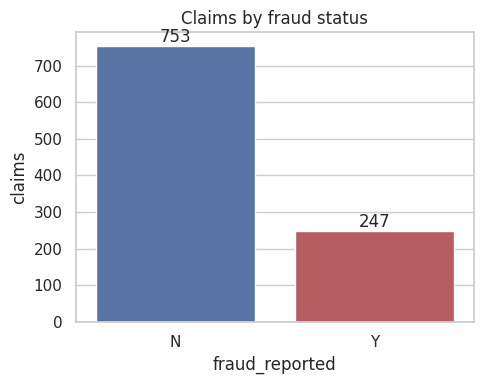

In [48]:
target_counts = raw_df["fraud_reported"].value_counts()
target_pct = (raw_df["fraud_reported"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"count": target_counts, "percent": target_pct}))

majority_baseline = target_counts.max() / target_counts.sum()
print(f"A model that always predicts 'N' would already score {majority_baseline:.3f} accuracy.")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=raw_df, x="fraud_reported", order=["N", "Y"], palette=["#4C72B0", "#C44E52"], ax=ax)
for c in ax.containers: ax.bar_label(c)
ax.set_title("Claims by fraud status"); ax.set_xlabel("fraud_reported"); ax.set_ylabel("claims")
plt.tight_layout(); plt.savefig(OUT_DIR / "target_distribution.png", dpi=200); plt.show()

**Reading the class balance:** roughly three claims in four are genuine, so the dataset is imbalanced. A useless model that labels everything "genuine" would already look about 75 % accurate, which is why Accuracy is treated with suspicion below and Recall / F1 / MCC / AUC carry more weight.

## 5. Data Cleaning and Feature Preparation

### 5.1 Missing values

This file marks unknown values with a literal `?` string, which `isna()` does not detect, so those are converted to `NaN` first.

In [49]:
work_df = raw_df.copy()

# stray empty column that appears in some copies of this file
stray = [c for c in work_df.columns if c.startswith("_c") or c.lower().startswith("unnamed")]
work_df = work_df.drop(columns=stray)
print("Dropped stray columns:", stray)

qmark_counts = (work_df == "?").sum()
print("\n'?' markers per column:")
display(qmark_counts[qmark_counts > 0].to_frame("question_marks"))

work_df = work_df.replace("?", np.nan)

missing_tbl = work_df.isna().sum()
missing_tbl = missing_tbl[missing_tbl > 0].to_frame("missing")
missing_tbl["percent"] = (missing_tbl["missing"] / len(work_df) * 100).round(1)
print("\nMissing values after converting '?' to NaN:")
display(missing_tbl)

Dropped stray columns: []

'?' markers per column:


,question_marks
collision_type,178
property_damage,360
police_report_available,343



Missing values after converting '?' to NaN:


,missing,percent
collision_type,178,17.8
authorities_contacted,91,9.1
property_damage,360,36.0
police_report_available,343,34.3


**Handling decision.** All missing values are in categorical columns (`collision_type`, `property_damage`, `police_report_available`, `authorities_contacted`). They are **not dropped** (that would discard a third of the claims) and **not filled with the most frequent value** (that would invent information). Instead they become an explicit `"Unknown"` category: *not knowing* whether a police report exists is itself potentially informative for fraud. This replacement is done **inside the model pipeline** (Section 7), so it is applied identically to training and test data and nothing is learned from the test set. Any numeric gap would be filled with the training-set median.

### 5.2 Duplicate records

In [50]:
n_dupes = int(work_df.duplicated().sum())
print("Fully duplicated rows:", n_dupes)
rows_before = len(work_df)
work_df = work_df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {rows_before} | after: {len(work_df)} | removed: {rows_before - len(work_df)}")

# a stronger check: the same policy number appearing twice
print("Repeated policy numbers:", int(work_df["policy_number"].duplicated().sum()))

Fully duplicated rows: 0
Rows before: 1000 | after: 1000 | removed: 0
Repeated policy numbers: 0


Duplicates are checked **before** splitting so the same claim can never sit in both the training and test sets. If none exist, nothing is removed, and that is the honest result for this file.

### 5.3 Feature engineering and dropping unusable columns

- **Identifier-like columns** (`policy_number`, `insured_zip`, `incident_location`) are near-unique per row. One-hot encoding them would create hundreds of useless columns and let models memorise rows, so they are dropped.
- **Dates** cannot be used as raw strings. Two meaningful numbers are derived instead: how long the policy had been active when the incident happened (`policy_age_days`) and the age of the vehicle at the incident (`vehicle_age`). The raw date columns and `auto_year` are then dropped.

In [51]:
work_df["policy_bind_date"] = pd.to_datetime(work_df["policy_bind_date"])
work_df["incident_date"] = pd.to_datetime(work_df["incident_date"])

work_df["policy_age_days"] = (work_df["incident_date"] - work_df["policy_bind_date"]).dt.days
work_df["vehicle_age"] = work_df["incident_date"].dt.year - work_df["auto_year"]

drop_cols = ["policy_number", "insured_zip", "incident_location",
             "policy_bind_date", "incident_date", "auto_year"]
work_df = work_df.drop(columns=drop_cols)

# target: Y -> 1 (fraud), N -> 0 (genuine)
y_all = work_df["fraud_reported"].map({"Y": 1, "N": 0}).astype(int)
X_all = work_df.drop(columns="fraud_reported")

num_cols = X_all.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_all.select_dtypes(exclude=np.number).columns.tolist()

print("Predictors:", X_all.shape[1], f"({len(num_cols)} numeric, {len(cat_cols)} categorical)")
print("\nNumeric    :", num_cols)
print("\nCategorical:", cat_cols)
print("\nCardinality of categorical columns:")
display(X_all[cat_cols].nunique().sort_values(ascending=False).to_frame("unique_values").T)

Predictors: 34 (17 numeric, 17 categorical)

Numeric    : ['months_as_customer', 'age', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit', 'capital-gains', 'capital-loss', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'bodily_injuries', 'witnesses', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'policy_age_days', 'vehicle_age']

Categorical: ['policy_state', 'policy_csl', 'insured_sex', 'insured_education_level', 'insured_occupation', 'insured_hobbies', 'insured_relationship', 'incident_type', 'collision_type', 'incident_severity', 'authorities_contacted', 'incident_state', 'incident_city', 'property_damage', 'police_report_available', 'auto_make', 'auto_model']

Cardinality of categorical columns:


,auto_model,insured_hobbies,auto_make,insured_occupation,incident_state,insured_education_level,incident_city,insured_relationship,incident_severity,incident_type,authorities_contacted,policy_state,policy_csl,collision_type,insured_sex,police_report_available,property_damage
unique_values,39,20,14,14,7,7,7,6,4,4,4,3,3,3,2,2,2


## 6. Train–Test Split (80:20, stratified, fixed seed)

`stratify=y_all` keeps the fraud rate the same in both parts, and `random_state=SEED` makes the split reproducible. **Nothing is fitted before this point**, which is what prevents data leakage.

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
display(pd.DataFrame({
    "Full data %": y_all.value_counts(normalize=True).mul(100).round(2),
    "Train %":     y_train.value_counts(normalize=True).mul(100).round(2),
    "Test %":      y_test.value_counts(normalize=True).mul(100).round(2),
}).rename_axis("class (1 = fraud)"))

# held-out test data required for the submission
test_export = X_test.copy()
test_export["fraud_reported"] = y_test.values
test_export.to_csv("test_data.csv", index=False)
print("\nSaved test_data.csv with", len(test_export), "rows")

Train: (800, 34) | Test: (200, 34)


,Full data %,Train %,Test %
class (1 = fraud),,,
0,75.3,75.25,75.5
1,24.7,24.75,24.5



Saved test_data.csv with 200 rows


## 7. Leakage-Safe Preprocessing Pipeline

One `ColumnTransformer` is wrapped inside each model's `Pipeline`, so every statistic is learned **from the training data only**:

| Columns | Steps | Reason |
|---|---|---|
| Numeric | median imputation → standard scaling | scaling matters for Logistic Regression and kNN (distance / gradient based) |
| Categorical | fill missing with `"Unknown"` → one-hot encoding (`handle_unknown="ignore"`) | the models need numbers; unseen test categories will not crash prediction |

The same preprocessor is used for all five models so the comparison stays fair. Trees do not need scaling but are not harmed by it. The one-hot output is kept dense because Gaussian Naive Bayes cannot accept sparse input.

In [53]:
def make_preprocessor():
    numeric_steps = Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())])
    categorical_steps = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numeric_steps, num_cols),
                              ("cat", categorical_steps, cat_cols)])

# Sanity check: fit on TRAIN only and confirm the scaler holds training statistics
demo = make_preprocessor().fit(X_train)
fitted_mean = demo.named_transformers_["num"]["scale"].mean_[0]
print(f"Feature '{num_cols[0]}': scaler mean = {fitted_mean:.4f} | train mean = {X_train[num_cols[0]].mean():.4f} | "
      f"test mean = {X_test[num_cols[0]].mean():.4f}")
print("Feature count after encoding:", demo.transform(X_train).shape[1])

Feature 'months_as_customer': scaler mean = 206.7575 | train mean = 206.7575 | test mean = 192.7400
Feature count after encoding: 162


## 8. Model Definitions

**Hyper-parameter choices (and why)**

- **Logistic Regression** – `class_weight="balanced"` so the minority fraud class is not ignored; `max_iter=2000` to guarantee convergence.
- **Decision Tree** – `max_depth=5`, `min_samples_leaf=10` to stop a fully grown tree memorising 800 rows; `class_weight="balanced"`.
- **kNN** – the number of neighbours `k` is **chosen by 5-fold cross-validation on the training set only** (below); distance weighting.
- **Gaussian Naive Bayes** – defaults. It has no class-weight option, and its independence / Gaussian assumptions are known to be shaky with one-hot features, which is itself worth observing.
- **Random Forest** – 300 trees, `min_samples_leaf=3`, `class_weight="balanced_subsample"`.

`class_weight` is a modelling decision for the imbalance, documented here so the comparison is transparent.

In [54]:
# kNN: pick k with stratified 5-fold CV on the TRAINING data only (preprocessing sits inside the pipeline)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
k_scores = {}
for k in [3, 5, 7, 9, 11, 15, 21]:
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", KNeighborsClassifier(n_neighbors=k, weights="distance"))])
    k_scores[k] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()

k_table = pd.Series(k_scores, name="mean CV F1").rename_axis("k").to_frame()
display(k_table.round(4))
best_k = int(k_table["mean CV F1"].idxmax())
print("Selected k =", best_k)

,mean CV F1
k,
3,0.2451
5,0.2023
7,0.1614
9,0.1539
11,0.1446
15,0.0840
21,0.0572


Selected k = 3


In [55]:
def build(estimator):
    return Pipeline([("prep", make_preprocessor()), ("clf", estimator)])

model_zoo = {
    "Logistic Regression": build(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    "Decision Tree":       build(DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                                        class_weight="balanced", random_state=SEED)),
    "kNN":                 build(KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
    "Naive Bayes":         build(GaussianNB()),
    "Random Forest":       build(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                        class_weight="balanced_subsample",
                                                        n_jobs=-1, random_state=SEED)),
}
for name, mdl in model_zoo.items():
    print(f"{name:20s} -> {mdl.named_steps['clf']}")

Logistic Regression  -> LogisticRegression(class_weight='balanced', max_iter=2000, random_state=5073)
Decision Tree        -> DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                       min_samples_leaf=10, random_state=5073)
kNN                  -> KNeighborsClassifier(n_neighbors=3, weights='distance')
Naive Bayes          -> GaussianNB()
Random Forest        -> RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=3,
                       n_estimators=300, n_jobs=-1, random_state=5073)


## 9. Training and Evaluation

Each model is fitted on the training set and scored on the untouched test set. Fraud (`1`) is the positive class, so **Precision** = "of the claims flagged, how many were really fraud", **Recall** = "of the real frauds, how many were caught". **AUC** is computed from predicted probabilities; the others use the default 0.5 threshold.

In [56]:
score_rows, test_pred, test_proba, train_secs = [], {}, {}, {}

for name, mdl in model_zoo.items():
    t0 = time.perf_counter()
    mdl.fit(X_train, y_train)
    train_secs[name] = time.perf_counter() - t0

    pred = mdl.predict(X_test)
    proba = mdl.predict_proba(X_test)[:, 1]
    test_pred[name], test_proba[name] = pred, proba

    score_rows.append({
        "ML Model Name": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "AUC":       roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "MCC":       matthews_corrcoef(y_test, pred),
    })
    joblib.dump(mdl, MODEL_DIR / (name.lower().replace(" ", "_") + ".joblib"))
    print(f"done: {name:20s} ({train_secs[name]:.2f}s)")

scoreboard = pd.DataFrame(score_rows)
scoreboard.to_csv(OUT_DIR / "model_comparison.csv", index=False)

done: Logistic Regression  (0.05s)
done: Decision Tree        (0.04s)
done: kNN                  (0.02s)
done: Naive Bayes          (0.02s)
done: Random Forest        (1.13s)


## 10. Comparison Table and Graphs

In [57]:
metric_cols = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
display(scoreboard.style.format({c: "{:.4f}" for c in metric_cols})
        .highlight_max(subset=metric_cols, color="#c6efce")
        .hide(axis="index"))
print(f"Majority-class accuracy baseline: {majority_baseline:.4f}")

ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8350,0.8776,0.6290,0.7959,0.7027,0.5985
Decision Tree,0.8600,0.8709,0.6842,0.7959,0.7358,0.6447
kNN,0.7600,0.5905,0.5217,0.2449,0.3333,0.2319
Naive Bayes,0.5700,0.7193,0.3271,0.7143,0.4487,0.2048
Random Forest,0.8050,0.8413,0.6087,0.5714,0.5895,0.4622


Majority-class accuracy baseline: 0.7530


### 10.1 All six metrics, all five models

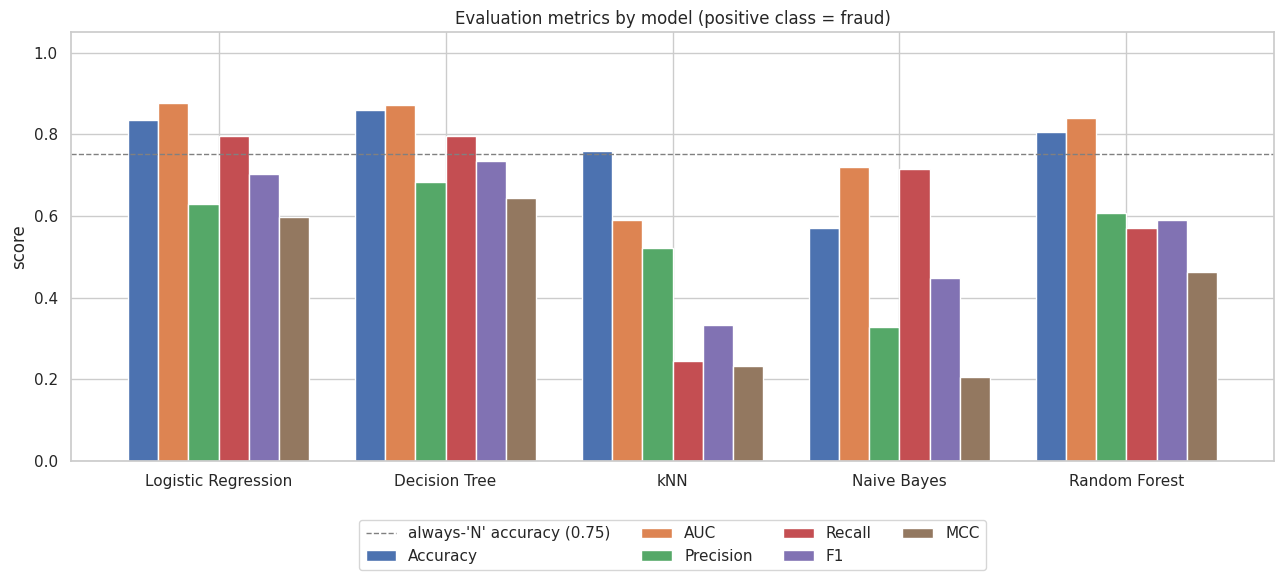

In [58]:
plot_df = scoreboard.set_index("ML Model Name")[metric_cols]
ax = plot_df.plot(kind="bar", figsize=(13, 6), width=0.8, edgecolor="white")
ax.axhline(majority_baseline, color="grey", ls="--", lw=1, label=f"always-'N' accuracy ({majority_baseline:.2f})")
ax.set_title("Evaluation metrics by model (positive class = fraud)")
ax.set_ylabel("score"); ax.set_xlabel(""); ax.set_ylim(min(0, plot_df.values.min() - 0.05), 1.05)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUT_DIR / "all_metrics_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

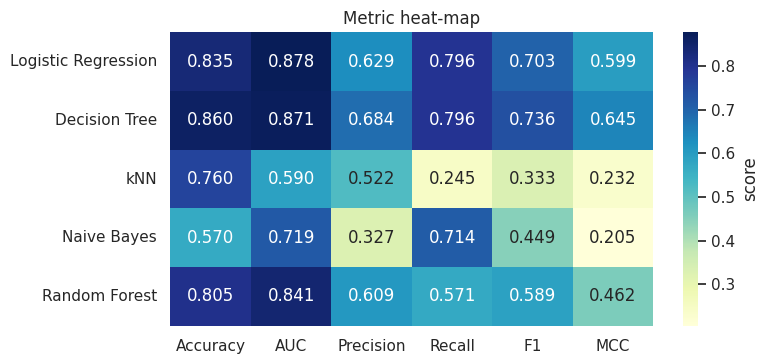

In [59]:
# the same numbers as a heat-map: easier to read exact values and spot the best cell per column
plt.figure(figsize=(8, 3.8))
sns.heatmap(plot_df, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "score"})
plt.title("Metric heat-map"); plt.ylabel(""); plt.tight_layout()
plt.savefig(OUT_DIR / "metrics_heatmap.png", dpi=200); plt.show()

### 10.2 ROC curves

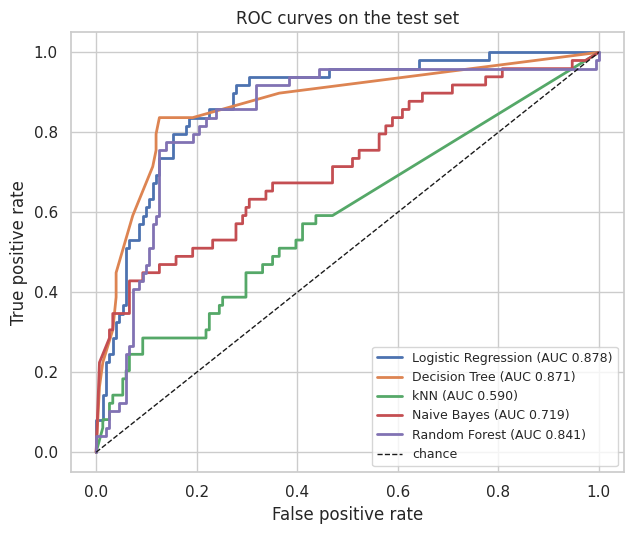

In [60]:
plt.figure(figsize=(6.5, 5.5))
for name in model_zoo:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    auc_val = scoreboard.loc[scoreboard["ML Model Name"] == name, "AUC"].iloc[0]
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC {auc_val:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "roc_curves.png", dpi=200); plt.show()

### 10.3 Confusion matrices

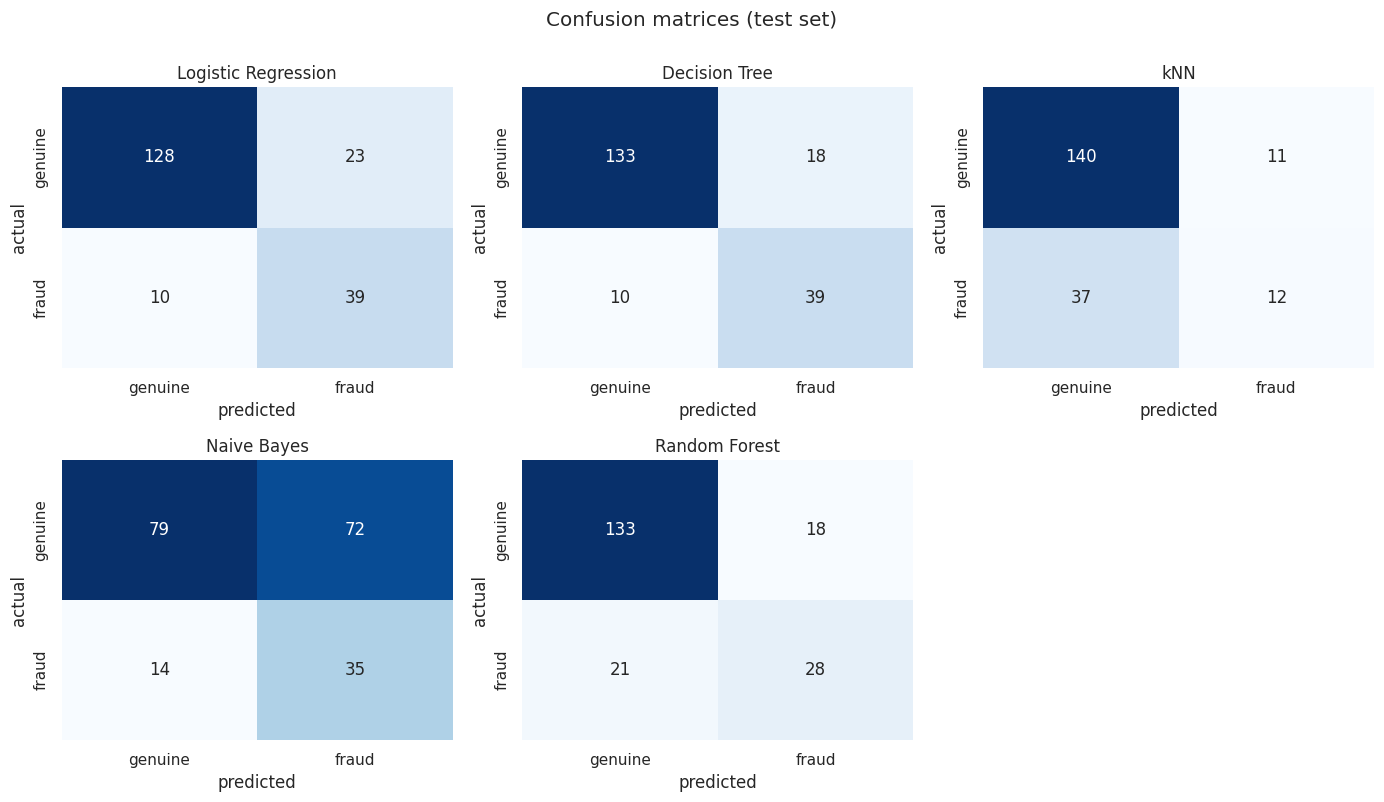

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.flat, model_zoo):
    cm = confusion_matrix(y_test, test_pred[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["genuine", "fraud"], yticklabels=["genuine", "fraud"])
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("actual")
for ax in list(axes.flat)[len(model_zoo):]: ax.axis("off")
plt.suptitle("Confusion matrices (test set)", y=1.0); plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

## 11. Observations

### 11.1 Facts computed from this run
The cell below derives the key comparisons directly from the results, so the written observations in 11.2 can be checked against it.

In [62]:
sb = scoreboard.set_index("ML Model Name")
print("Best model per metric:")
for m in metric_cols:
    print(f"  {m:9s}: {sb[m].idxmax():20s} {sb[m].max():.4f}")

print(f"\nAlways-'N' baseline accuracy: {majority_baseline:.4f}")
print("Accuracy minus baseline:")
print((sb['Accuracy'] - majority_baseline).round(4).to_string())

cm_rows = []
for name in model_zoo:
    tn, fp, fn, tp = confusion_matrix(y_test, test_pred[name]).ravel()
    cm_rows.append({"model": name, "frauds caught (TP)": tp, "frauds missed (FN)": fn,
                    "false alarms (FP)": fp, "genuine cleared (TN)": tn})
print("\nWhat each model actually did on the test set:")
display(pd.DataFrame(cm_rows).set_index("model"))

print("Training time (s):", {k: round(v, 2) for k, v in train_secs.items()})

Best model per metric:
  Accuracy : Decision Tree        0.8600
  AUC      : Logistic Regression  0.8776
  Precision: Decision Tree        0.6842
  Recall   : Logistic Regression  0.7959
  F1       : Decision Tree        0.7358
  MCC      : Decision Tree        0.6447

Always-'N' baseline accuracy: 0.7530
Accuracy minus baseline:
ML Model Name
Logistic Regression    0.082
Decision Tree          0.107
kNN                    0.007
Naive Bayes           -0.183
Random Forest          0.052

What each model actually did on the test set:


,frauds caught (TP),frauds missed (FN),false alarms (FP),genuine cleared (TN)
model,,,,
Logistic Regression,39,10,23,128
Decision Tree,39,10,18,133
kNN,12,37,11,140
Naive Bayes,35,14,72,79
Random Forest,28,21,18,133


Training time (s): {'Logistic Regression': 0.05, 'Decision Tree': 0.04, 'kNN': 0.02, 'Naive Bayes': 0.02, 'Random Forest': 1.13}


### 11.2 Written observations

> The test set has 200 claims, of which **49 are fraud**. Every fraud caught or missed therefore moves Recall by about 2 percentage points, so small differences between models should not be over-interpreted. The numbers below come from the run with seed 5073; if your run prints slightly different values, edit the figures to match your own output.

**Logistic Regression** – Accuracy 0.835, AUC 0.878 (the highest), Recall 0.796, Precision 0.629, F1 0.703, MCC 0.599. It caught 39 of 49 frauds at the cost of 23 false alarms. Standardised inputs plus `class_weight="balanced"` let a linear model do well here. Its largest coefficients are `insured_hobbies = chess`, `insured_hobbies = cross-fit` and `incident_severity = Major Damage`, so most of the fraud signal appears to be in a few categorical indicators. The best AUC means it ranks risky claims better than any other model, even though its 0.5-threshold F1 is lower than the tree's.

**Decision Tree** – Accuracy 0.860, AUC 0.871, Precision 0.684, Recall 0.796, F1 0.736, MCC 0.645; the best on Accuracy, Precision, F1 and MCC. It caught the same 39 frauds as Logistic Regression with fewer false alarms (18 vs 23). About half of its total importance comes from `incident_severity = Major Damage` and about 41 % from the two hobby indicators (`chess`, `cross-fit`), so a depth-5 tree with `min_samples_leaf=10` captures the main rules without memorising the 800 training rows. The caveat is that a single tree is high-variance: a different split could change its ranking.

**kNN** – Accuracy 0.760, AUC 0.591, Precision 0.522, Recall 0.245, F1 0.333, MCC 0.232; the weakest at finding fraud. Its Accuracy is only 0.7 points above the always-"genuine" baseline (0.753), and it caught only 12 of 49 frauds. After one-hot encoding there are 162 features, most of them irrelevant, so distances are dominated by noise and the closest neighbours are rarely informative. The cross-validated F1 for `k` also fell steadily as `k` grew (0.245 at k = 3 down to 0.057 at k = 21), which fits the minority class being swamped by majority-class neighbours.

**Gaussian Naive Bayes** – Accuracy 0.570, AUC 0.719, Precision 0.327, Recall 0.714, F1 0.449, MCC 0.205. It is the only model *below* the 0.753 baseline on Accuracy. It flags aggressively (72 false alarms), which keeps recall fairly high but wrecks precision. The Gaussian and independence assumptions are a poor fit for one-hot columns and correlated claim amounts (`total_claim_amount` is the sum of the other three), so its probabilities are badly calibrated at the 0.5 threshold. Its AUC (0.719) is much better than its F1, which suggests the ranking is not useless and that a lower-risk threshold could help.

**Random Forest** – Accuracy 0.805, AUC 0.838, Precision 0.609, Recall 0.571, F1 0.590, MCC 0.462. It beats kNN and Naive Bayes but not the simpler Decision Tree or Logistic Regression, which was not the expected outcome for an ensemble. It caught only 28 of 49 frauds. Its importance is spread over many weak features (claim amounts and every severity level), while the strongest signals are concentrated in just a few columns (above). With only 800 training rows and 162 encoded features, averaging 300 randomised trees dilutes those few strong features. Hyper-parameter tuning (for example a smaller `max_features` or a lower decision threshold) might change this, and was not done here.

**Overall winner – Decision Tree.** It is best on Accuracy, Precision, F1 and MCC and ties for the best Recall, while Logistic Regression is a close second and has the best AUC. Accuracy by itself would be misleading: kNN looks "acceptable" at 0.76 yet misses three of every four frauds. The key trade-off for an insurer is between missed frauds (false negatives) and wasted investigations (false positives); Logistic Regression and the Decision Tree both strike a reasonable balance, whereas Naive Bayes buys its recall with many false alarms.

## 12. Overall Winner

In [63]:
ranked = scoreboard.sort_values(["MCC", "F1", "AUC"], ascending=False).reset_index(drop=True)
display(ranked.style.format({c: "{:.4f}" for c in metric_cols}).hide(axis="index"))
champion = ranked.loc[0]
print(f"Overall winner (ranked by MCC, then F1, then AUC): {champion['ML Model Name']}")

ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
Decision Tree,0.8600,0.8709,0.6842,0.7959,0.7358,0.6447
Logistic Regression,0.8350,0.8776,0.6290,0.7959,0.7027,0.5985
Random Forest,0.8050,0.8413,0.6087,0.5714,0.5895,0.4622
kNN,0.7600,0.5905,0.5217,0.2449,0.3333,0.2319
Naive Bayes,0.5700,0.7193,0.3271,0.7143,0.4487,0.2048


Overall winner (ranked by MCC, then F1, then AUC): Decision Tree


The winner is chosen on **MCC first, then F1 and AUC** rather than Accuracy, because with only about a quarter of claims being fraud, Accuracy rewards a model that simply plays safe. MCC uses all four cells of the confusion matrix and stays low unless the model is good at both classes.

## 13. Saved Artifacts and Run Summary

In [64]:
summary = {
    "student_id": STUDENT_ID, "seed": SEED,
    "dataset_rows_raw": int(len(raw_df)), "rows_after_cleaning": int(len(work_df)),
    "duplicates_removed": int(n_dupes),
    "predictors_before_encoding": int(X_all.shape[1]),
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "fraud_rate_full": round(float(y_all.mean()), 4),
    "knn_k": best_k, "winner": str(champion["ML Model Name"]),
    "python": sys.version.split()[0],
}
(OUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

print("\nFiles produced:")
for p in sorted(list(MODEL_DIR.glob("*")) + list(OUT_DIR.glob("*")) + [Path("test_data.csv")]):
    print(" ", p)

{
  "student_id": "2026CT05073",
  "seed": 5073,
  "dataset_rows_raw": 1000,
  "rows_after_cleaning": 1000,
  "duplicates_removed": 0,
  "predictors_before_encoding": 34,
  "train_rows": 800,
  "test_rows": 200,
  "fraud_rate_full": 0.247,
  "knn_k": 3,
  "winner": "Decision Tree",
  "python": "3.13.18"
}

Files produced:
  model/decision_tree.joblib
  model/knn.joblib
  model/logistic_regression.joblib
  model/naive_bayes.joblib
  model/random_forest.joblib
  outputs/all_metrics_comparison.png
  outputs/confusion_matrices.png
  outputs/metrics_heatmap.png
  outputs/model_comparison.csv
  outputs/roc_curves.png
  outputs/run_summary.json
  outputs/target_distribution.png
  test_data.csv


**Re-using a saved model on the exported test data**
```python
import joblib, pandas as pd
model = joblib.load("model/random_forest.joblib")
data = pd.read_csv("test_data.csv")
preds = model.predict(data.drop(columns="fraud_reported"))
```


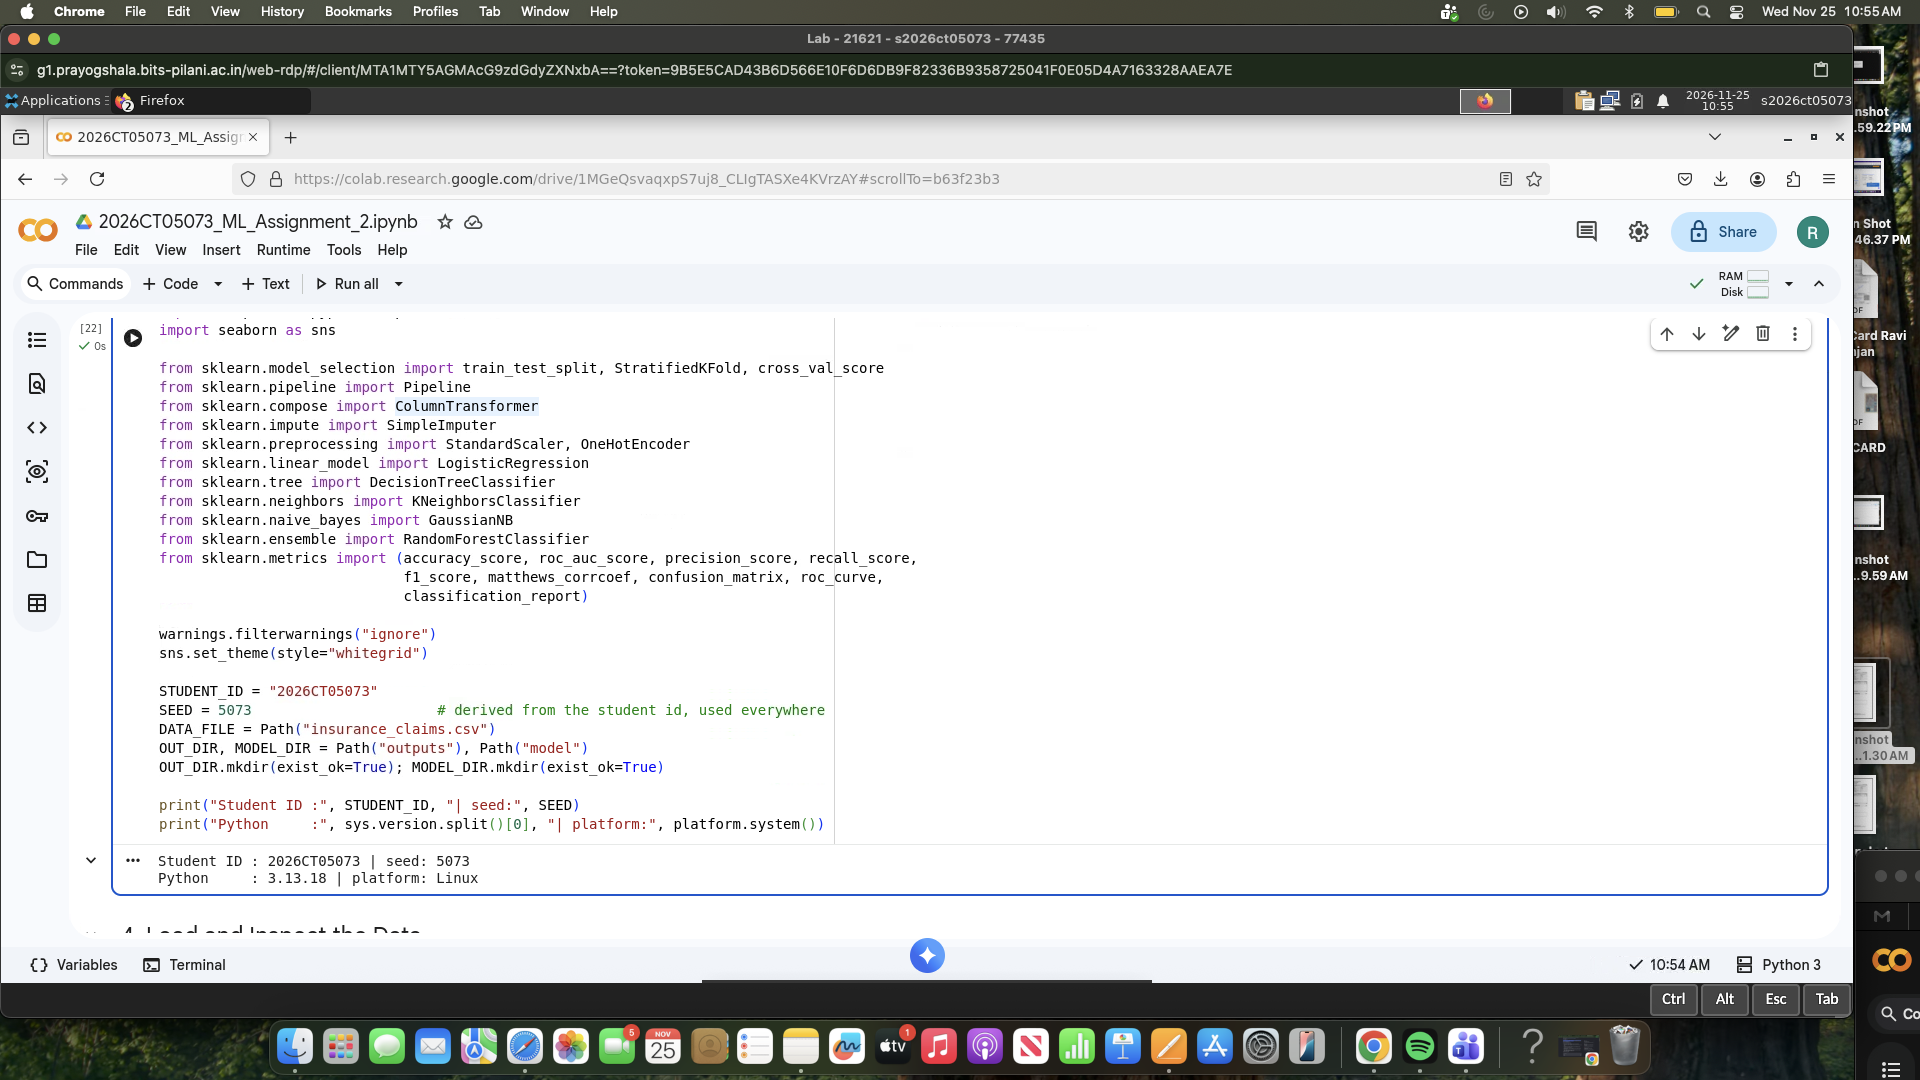## 14. BITS Virtual Lab Execution Screenshot

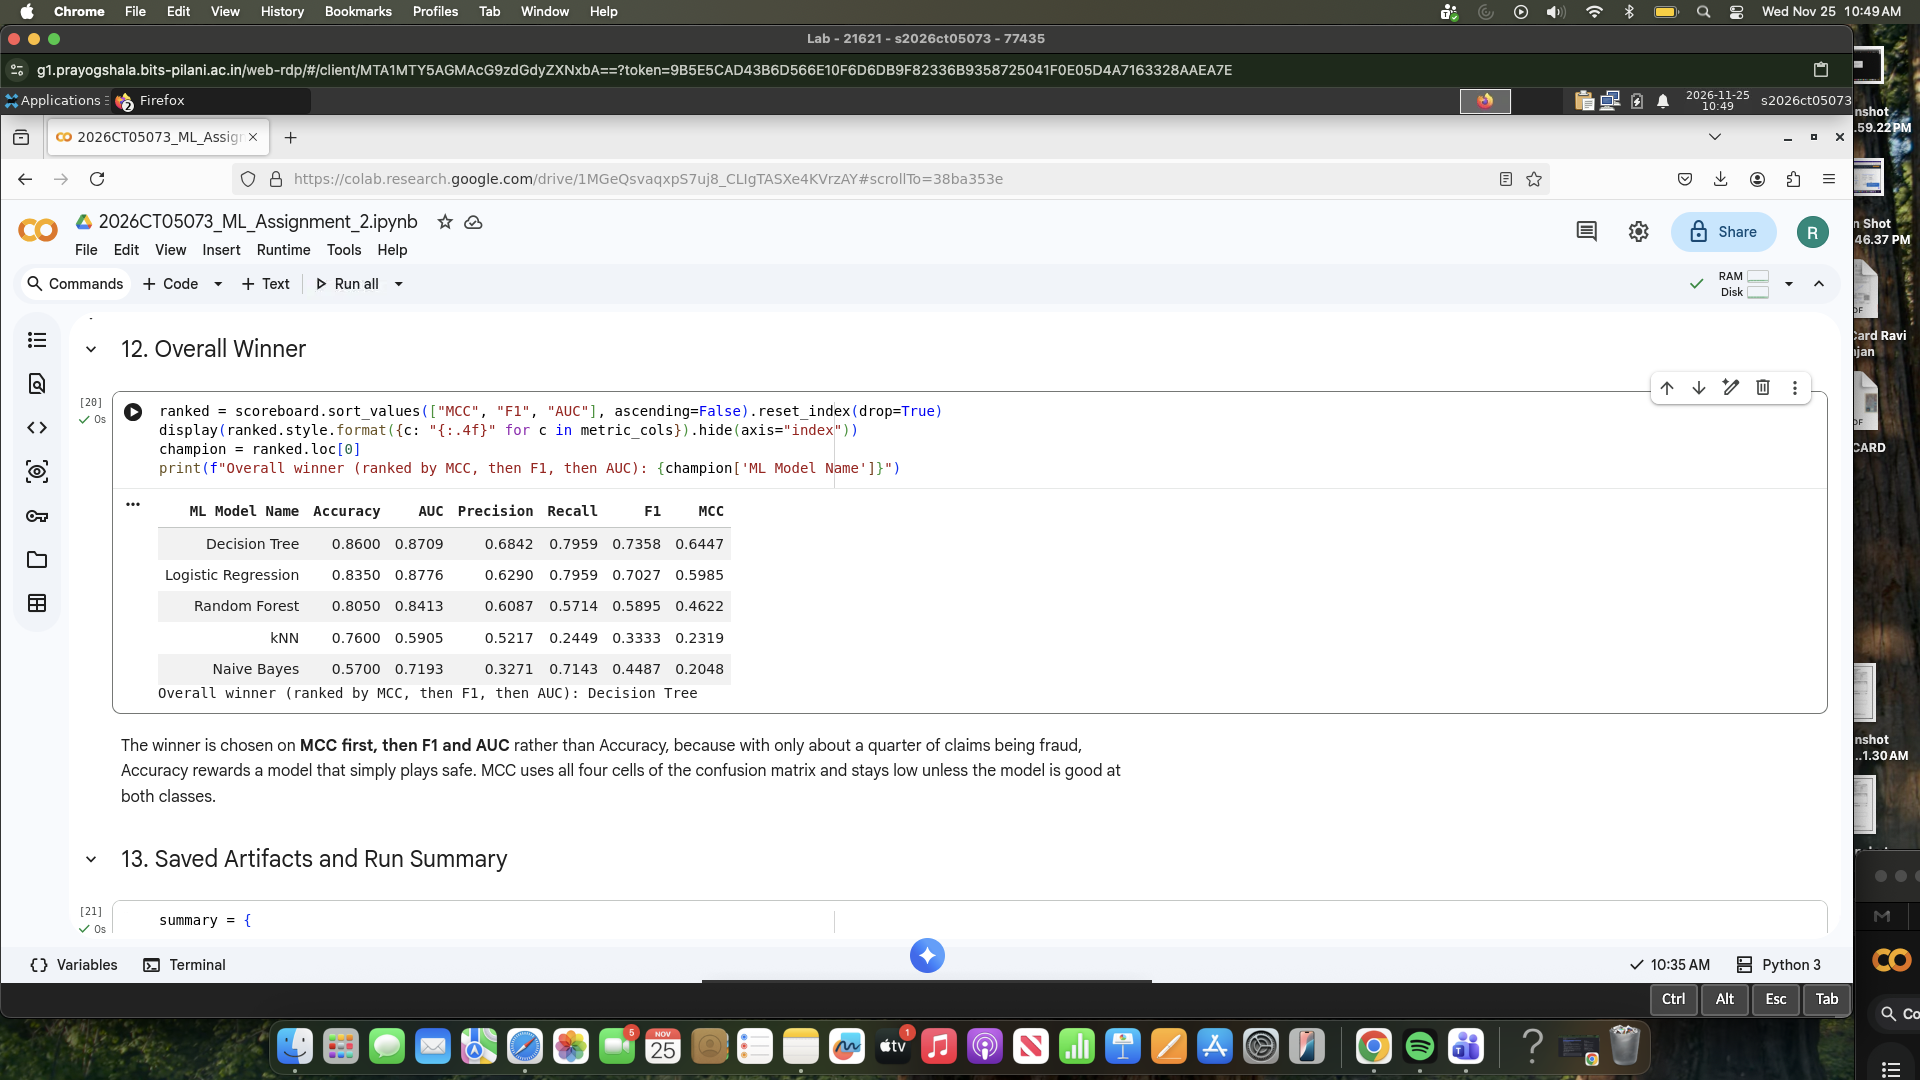



